In [1]:
import os
import glob
import pickle
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.size']    = 8.0
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family']  = 'Arial'


In [2]:
# parameters (match the rest of the pipeline)
Fs          = 3e4
TimeHistory = 20e-3   # 20 ms pre-spike window
TimePost    = 2e-3    # 2 ms post-spike

# clipped pickles from both moth-folder locations
pickle_paths = glob.glob('./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/*.pickle')
out_path = './dataFolder/Figures/5b_Latency/selectedUnits/'
os.makedirs(out_path, exist_ok=True)

print(f'Found {len(pickle_paths)} pickles:')
for p in pickle_paths:
    print(f'  {p}')

Found 12 pickles:
  ./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m29_unit_2_EncodingModel.pickle
  ./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m30_unit_2_EncodingModel.pickle
  ./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m31_unit_3_EncodingModel.pickle
  ./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m29_unit_3_EncodingModel.pickle
  ./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m11_unit_1_EncodingModel.pickle
  ./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m31_unit_2_EncodingModel.pickle
  ./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m31_unit_1_EncodingModel.pickle
  ./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m11_unit_2_EncodingModel.pickle
  ./dataFolder/5_1DCompModel/U

In [3]:
# pre-spike window in samples (indices 0 to pre_samples-1 are time BEFORE spike)
pre_samples = int(TimeHistory * Fs)   # 600 samples = 20 ms

records = []

for fp in pickle_paths:
    base   = os.path.basename(fp)
    moth   = base.split('_')[0]                 # e.g. 'm23' or 'm11'
    unit   = '_'.join(base.split('_')[1:3])     # e.g. 'unit_1'

    with open(fp, 'rb') as f:
        savedModel = pickle.load(f)
    sta = np.asarray(savedModel[1])             # STA array, length = pre_samples + post_samples

    # take only the pre-spike portion (indices 0 .. pre_samples-1)
    sta_pre = sta[:pre_samples]

    # peak = index of max |STA| within pre-spike window
    peak_idx   = int(np.argmax(np.abs(sta_pre)))
    peak_value = float(sta_pre[peak_idx])
    peak_sign  = 'positive' if peak_value > 0 else 'negative'

    # convert index to ms BEFORE spike
    # peak_idx=0 -> 20 ms before;  peak_idx=pre_samples-1 -> ~0 ms before
    latency_ms = (pre_samples - peak_idx) / Fs * 1000.0

    records.append({
        'moth':       moth,
        'unit':       unit,
        'latency_ms': latency_ms,
        'peak_value': peak_value,
        'peak_sign':  peak_sign,
    })

df = pd.DataFrame(records).sort_values(['moth', 'unit']).reset_index(drop=True)
csv_out_path = './dataFolder/5b_Latency/selectedUnits_peak/'
os.makedirs(csv_out_path, exist_ok=True)
df.to_csv(csv_out_path + 'absolute_peak.csv', index=False)

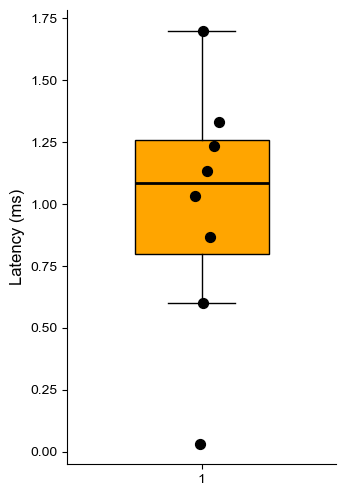


Saved to: ./dataFolder/Figures/5b_Latency/selectedUnits/
  median: 1.083 ms
  mean:   0.992 ms
  SD:     0.505 ms
  range:  0.033 to 1.700 ms


In [4]:
rng = np.random.default_rng(0)   # reproducible jitter

fig, ax = plt.subplots(figsize=(3.5, 5))

bp = ax.boxplot(df['latency_ms'].values,
                widths=0.5,
                patch_artist=True,
                showfliers=False,
                boxprops=dict(facecolor='orange', edgecolor='black'),
                medianprops=dict(color='black', linewidth=2),
                whiskerprops=dict(color='black'),
                capprops=dict(color='black'))

# overlay individual unit points with horizontal jitter
x_jit = 1 + rng.normal(0, 0.05, size=len(df))
ax.scatter(x_jit, df['latency_ms'].values,
           s=50, edgecolor='black', facecolor='black', zorder=3)

# ax.set_xticks([1])
# ax.set_xticklabels(['All units'], fontsize=12)
ax.set_ylabel('Latency (ms)', fontsize=12)
# ax.set_title('Latency at Peak', fontsize=11)
ax.tick_params(labelsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
fig.savefig(out_path + 'STA_peak_latency_boxplot.pdf', bbox_inches='tight')
fig.savefig(out_path + 'STA_peak_latency_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

print(f'\nSaved to: {out_path}')
print(f'  median: {df["latency_ms"].median():.3f} ms')
print(f'  mean:   {df["latency_ms"].mean():.3f} ms')
print(f'  SD:     {df["latency_ms"].std():.3f} ms')
print(f'  range:  {df["latency_ms"].min():.3f} to {df["latency_ms"].max():.3f} ms')